# Instruction the lab-work #4
`TODO`: make the final .ipynb file in format `"{second_name}_{first_name}_{group_id}__lab_4.ipynb"`

First name     - Volodymyr

Second name    - Donets

Group          - KU-41

# Task description

## Watch these materials first

1. [Beyond Propensity: From traditional ML to Uplift Modelling](https://www.youtube.com/watch?v=UamvZ-J0eVA) -- I **highly recommend this video** to understand the basics of propensity and causal modelling.
2. [Uplift Modelling - throw away your churn model. Ivan Klimuk](https://www.youtube.com/watch?v=A6a1MbH4fFk) -- Example of practical application of Uplift modelling
3. [ARTICLE: 3.6 Uplift Modeling for Targeting](https://marketing-science-in-python.com/part3/sec3.6-uplift-modeling.html)
4. [Künzel et al. (2019), "Metalearners for estimating heterogeneous treatment effects using machine learning" (PNAS)](https://www.pnas.org/doi/epdf/10.1073/pnas.1804597116) — Foundational paper introducing the X-Learner and comparing S-, T-, and X-Learners.
5. [CausalML Documentation: Meta-Learner Algorithms](https://causalml.readthedocs.io/en/latest/methodology.html) & [scikit-uplift Tutorials](https://www.uplift-modeling.com/en/latest/user_guide/index.html) — Practical guides on uplift modeling and decile evaluation. And **I highly recommend click on these links too**.
6. [MineThatData E-Mail Analytics Challenge by Kevin Hillstrom](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html) — Classical benchmark dataset used in this lab's reference pipeline.

## Overall description

In this lab work, you will transition from traditional predictive modeling to **Causal Inference and Uplift Modeling**. Standard machine learning models estimate the probability of an outcome $P(Y = 1 \mid X)$, which tells us *who is likely to convert*, but not *who will convert **because** of our intervention (treatment)*. Causal modeling addresses this gap by estimating the **Conditional Average Treatment Effect (CATE)**—also known as **Uplift**—defined as the incremental change in outcome probability caused by an action.

This assignment is divided into two interconnected parts:
- **Part I. Propensity Modeling**: Estimating treatment assignment propensity $e(x) = P(T = 1 \mid X = x)$ and baseline conversion propensity $P(Y = 1 \mid X = x)$, evaluating model calibration, classification performance, and **Deciles Lift** ranking.
- **Part II. Uplift Modeling (Causal Modeling)**: Designing, training, and comparing fundamental Meta-Learner architectures—**S-Learner (Single-Model)**, **T-Learner (Two-Model)**, and **X-Learner (Cross-Model)**—to estimate heterogeneous treatment effects and evaluate incremental gain across population deciles via **Deciles Uplift Plots** and **Qini / Cumulative Uplift Curves**.


## *Instructions for the work*

1. **Dataset Selection & Preparation**: Choose a classical uplift or marketing/retention campaign dataset (containing features $X$, binary or multi-arm treatment $T$, and target outcome $Y$). Perform exploratory data analysis (EDA), verify treatment/control group balance, encode categorical features, and perform a stratified Train/Test split preserving the joint $(T, Y)$ distribution.
2. **Review Baselines**: Carefully study the provided theoretical notes and reference implementations in this notebook to understand the data pipeline, propensity estimation, meta-learners, and decile-based lift/uplift evaluation.
3. **Part I — Propensity Modeling**: Develop and train propensity models (e.g., Logistic Regression, Random Forest, XGBoost/Gradient Boosting) to estimate:
    * Treatment assignment propensity $e(x) = P(T = 1 \mid X = x)$ (check covariate overlap / positivity assumption).
    * Outcome conversion propensity $P(Y = 1 \mid X = x)$ (evaluate with ROC-AUC, Precision/Recall, Brier score, and a **Deciles Lift Plot**).
4. **Part II — Uplift (Causal) Modeling**: Implement, train, and compare at least three meta-learner uplift paradigms on the same dataset:
    * **S-Learner (Single-Model)**: Uses treatment indicator $T$ as an explicit input feature in a single estimator.
    * **T-Learner (Two-Model)**: Trains two independent estimators on the Control ($T=0$) and Treatment ($T=1$) subpopulations.
    * **X-Learner (Cross-Model)**: Imputes counterfactual individual treatment effects using cross-group predictions and combines second-stage regressors weighted by the propensity score $e(x)$.
5. **Evaluation & Deciles Lift / Uplift Visualization**: Build a **Deciles Lift / Uplift Plot** showing the lift and net uplift ($\bar{Y}_{T=1} - \bar{Y}_{T=0}$) in each decile (from top 1st decile to 10th decile) for every model, alongside **Cumulative Uplift / Qini Curves** and **AUUC (Area Under the Uplift Curve)**. Write a comprehensive analytical conclusion comparing Propensity targeting vs. S-Learner, T-Learner, and X-Learner.

## Important

1. **No Single-Cell Solutions**: Do NOT write all your code in a single Jupyter Notebook cell. Your code must be logically separated. Single-cell notebooks will receive a grade of 0. If you need help structuring a notebook, ask the instructor or your peers. Alternatively, you may submit well-structured `.py` files alongside a `.pdf` report of your results.
2. **Academic Integrity**: Plagiarism is prohibited. Identical or copied works will automatically receive a grade of 0.
3. **Submission Format**: You are encouraged to solve this assignment in a separate `.ipynb` file. You may duplicate the provided template, clear the existing solution, and build your own.
4. **Mandatory Conclusions**: A project without a written analytical conclusion is incomplete. Do not forget to summarize your findings at the end of your notebook.

## How to get max num of points without personal work presentation.

As I told you, you can get the maximum mark for all lab works without personal presentation in case of using something different and additional depth of work.
So for this work you can:

1. `Track A`: Architectural & Meta-Learner Experimentation
Do not limit yourself to basic S/T/X-learners with a single base estimator. Implement additional causal methods such as **Class Transformation (Lai's / Jaskowski's Transformed Outcome)**, **R-Learner**, or **Doubly Robust (DR) Learner**, and compare multiple base learners (e.g., Logistic Regression vs. Random Forest vs. XGBoost vs. MLP Neural Network). Document why certain base learners regularize away the treatment feature in S-Learner and how X-Learner mitigates variance.

# Explanation to the theoretical concepts

## 1. Propensity Modeling vs. Uplift (Causal) Modeling

In a marketing, retention, or medical intervention scenario, each individual $i$ with feature vector $X_i$ has two potential outcomes under the **Rubin Causal Model (Potential Outcomes Framework)**:
- $Y_i(1)$: the outcome if the individual **receives the treatment** ($T_i = 1$).
- $Y_i(0)$: the outcome if the individual **does not receive the treatment** ($T_i = 0$, control).

Because we can never observe both $Y_i(1)$ and $Y_i(0)$ simultaneously for the same person (*the Fundamental Problem of Causal Inference*), we estimate the **Conditional Average Treatment Effect (CATE)**, or **Uplift**:

$$
	au(x) = \mathbb{E}[Y(1) - Y(0) \mid X = x] = P(Y = 1 \mid T = 1, X = x) - P(Y = 1 \mid T = 0, X = x)
$$

By contrast, **Propensity Modeling** estimates either:
1. **Conversion / Outcome Propensity**: $p(x) = P(Y = 1 \mid X = x)$ (or $P(Y = 1 \mid T = 1, X = x)$), which ranks customers by how likely they are to convert overall.
2. **Treatment Assignment Propensity Score**: $e(x) = P(T = 1 \mid X = x)$, the probability of receiving treatment given covariates $X$.

### Why Response Propensity Fails at Causal Targeting: The 4 Customer Types
Customers fall into four behavioral groups:
1. **Persuadables** ($Y(1)=1, Y(0)=0$, $	au > 0$): Convert *only if* treated. **Target these!**
2. **Sure Things** ($Y(1)=1, Y(0)=1$, $	au = 0$): Convert regardless of treatment. Targeting them wastes budget.
3. **Lost Causes** ($Y(1)=0, Y(0)=0$, $	au = 0$): Never convert regardless of treatment.
4. **Sleeping Dogs / Do-Not-Disturbs** ($Y(1)=0, Y(0)=1$, $	au < 0$): Would have converted organically, but treatment annoys them into churning or unsubscribing.

A standard **Propensity Model** ($P(Y=1 \mid X)$) assigns the highest scores to **Sure Things**, whereas an **Uplift Model** specifically isolates **Persuadables** and avoids **Sleeping Dogs**.

---

## 2. Meta-Learner Architectures: S-Learner, T-Learner, and X-Learner

Meta-learners decompose causal effect estimation into standard supervised learning subproblems using off-the-shelf base learners (e.g., Gradient Boosted Trees, Random Forests, Logistic Regression).

### A. S-Learner (Single-Model Learner)
The treatment indicator $T \in \{0, 1\}$ is concatenated directly with the feature matrix $X$ to train a **single** model $\hat{\mu}(x, t)$ predicting $Y$:

$$
\hat{	au}_{S}(x) = \hat{\mu}(x, T=1) - \hat{\mu}(x, T=0)
$$

- **Pros**: Simple, uses the entire dataset for training a single model.
- **Cons**: In high-dimensional feature spaces, tree-based models may rarely split on $T$, biasing $\hat{	au}_S(x)$ toward zero.

### B. T-Learner (Two-Model Learner)
Splits the data into two separate subpopulations and fits **two independent models**:
- $\hat{\mu}_1(x) = \mathbb{E}[Y \mid X = x, T = 1]$ trained exclusively on the **Treated** group ($T = 1$).
- $\hat{\mu}_0(x) = \mathbb{E}[Y \mid X = x, T = 0]$ trained exclusively on the **Control** group ($T = 0$).

$$
\hat{	au}_{T}(x) = \hat{\mu}_1(x) - \hat{\mu}_0(x)
$$

- **Pros**: Never ignores the treatment indicator; captures distinct response surfaces in control vs. treated arms.
- **Cons**: Suffers from high variance and independent regularization errors between $\hat{\mu}_1$ and $\hat{\mu}_0$, especially when treatment and control sample sizes are imbalanced.

### C. X-Learner (Cross-Model Learner)
Proposed by Künzel et al. (2019), the **X-Learner** uses cross-group information in three stages:
1. **Stage 1 (Outcome Models)**: Fit $\hat{\mu}_1(x)$ on treated data and $\hat{\mu}_0(x)$ on control data (identical to T-Learner).
2. **Stage 2 (Imputed Counterfactual Effects & Second-Stage Regressors)**: Compute imputed individual treatment effects for each group using the *opposite* group's model:
   $$
   	ilde{D}_i^1 = Y_i^1 - \hat{\mu}_0(X_i^1) \quad (	ext{for } T_i = 1), \qquad
   	ilde{D}_i^0 = \hat{\mu}_1(X_i^0) - Y_i^0 \quad (	ext{for } T_i = 0)
   $$
   Then train two regression models: $\hat{	au}_1(x)$ predicting $	ilde{D}^1$ from $X^1$, and $\hat{	au}_0(x)$ predicting $	ilde{D}^0$ from $X^0$.
3. **Stage 3 (Propensity-Weighted Combination)**: Combine $\hat{	au}_1(x)$ and $\hat{	au}_0(x)$ using the estimated **propensity score** $\hat{e}(x) = P(T = 1 \mid X = x)$:
   $$
   \hat{	au}_{X}(x) = \hat{e}(x)\,\hat{	au}_0(x) + \bigl(1 - \hat{e}(x)\bigr)\,\hat{	au}_1(x)
   $$
   When the treated group is much larger than the control group ($\hat{e}(x) 	o 1$), $\hat{\mu}_1$ is more accurate than $\hat{\mu}_0$, so X-Learner places greater weight on $\hat{	au}_0(x)$ (which relies on the more accurate $\hat{\mu}_1$).

---

## 3. Deciles Lift and Deciles Uplift Plots

To evaluate how well a model prioritizes individuals for intervention, we sort all test observations in **descending order** of their predicted score and partition them into $10$ equal-sized bins (**Deciles $d = 1, 2, \dots, 10$**, where Decile 1 is the top $10\%$ highest-scored individuals):

1. **Decile Lift (for Propensity Models)**:
   $$
   	ext{Lift}_d = \frac{\bar{Y}_d}{\bar{Y}_{	ext{overall}}}
   $$
   Shows how many times higher the conversion rate in decile $d$ is compared to random selection ($	ext{Lift} = 1.0$).

2. **Decile Uplift (for Causal / Uplift Models)**:
   Within each decile $d$, we compare the empirical conversion rate of treated vs. control individuals who fell into that decile:
   $$
   	ext{Uplift}_d = \frac{1}{|d_{T=1}|}\sum_{i \in d_{T=1}} Y_i - \frac{1}{|d_{T=0}|}\sum_{j \in d_{T=0}} Y_j = \bar{Y}_{d, T=1} - \bar{Y}_{d, T=0}
   $$
   A strong uplift model exhibits **monotonically decreasing uplift across deciles**: high positive uplift in Deciles 1–3 (*Persuadables*), near-zero uplift in middle deciles (*Sure Things* / *Lost Causes*), and zero or negative uplift in Decile 10 (*Sleeping Dogs*).


## Research more on:

1. Look-a-like modeling

# Datasets to consider

1. [Criteo Uplift Prediction Dataset (13.9M rows, Large-Scale Advertising Uplift)](https://huggingface.co/datasets/criteo/criteo-uplift/blob/main/criteo-research-uplift-v2.1.csv.gz)  -- has treatment column
2. [Kaggle: Marketing Promotion Campaign Uplift Modeling (Starbucks / Retail)](https://www.kaggle.com/datasets/davinwijaya/customer-retention) -- consider "offer" as treatment column
3. [Lenta Uplift Modeling Dataset (687K Grocery Retail Customers, scikit-uplift)](https://www.uplift-modeling.com/en/latest/api/datasets/fetch_lenta.html)
4. [X5 RetailHero Uplift Dataset (Retail SMS Campaign, scikit-uplift)](https://www.uplift-modeling.com/en/latest/api/datasets/fetch_x5.html)
5. [Kaggle: Bank Marketing Dataset (Propensity & Observational Campaign Modeling)](https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset)
6. [Kaggle: Telco Customer Churn Dataset (Retention Propensity & Simulated Uplift)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
7. [IHDP (Infant Health and Development Program) Semi-Synthetic Causal Dataset](https://www.kaggle.com/datasets/konradb/ihdp-data)

# Part I: Propensity Modeling & Deciles Lift Analysis

## 1.1. Import & install dependencies

In [ ]:
# Install required dependencies if not already present in the environment
%pip install numpy pandas scikit-learn xgboost matplotlib seaborn scipy

In [3]:
import os
import warnings
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")

# Set random seed for reproducibility
SEED = 42
np.random.seed(SEED)

# Configure visual style
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

## 1.2. Load & prepare the classical uplift dataset (Kevin Hillstrom MineThatData)

In [5]:
HILLSTROM_URL = (
    "http://www.minethatdata.com/"
    "Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv"
)


def load_hillstrom_dataset(local_dir: str = "src") -> pd.DataFrame:
    """
    Download (if not cached locally) and load the classical Kevin Hillstrom
    MineThatData E-Mail Analytics dataset (64,000 customer records).
    """
    os.makedirs(local_dir, exist_ok=True)
    local_path = os.path.join(local_dir, "hillstrom_email_marketing.csv")

    if not os.path.exists(local_path):
        print(f"Downloading Hillstrom dataset from {HILLSTROM_URL} ...")
        urllib.request.urlretrieve(HILLSTROM_URL, local_path)
        print(f"Saved dataset to '{local_path}'.")
    else:
        print(f"Loading cached Hillstrom dataset from '{local_path}'.")

    df = pd.read_csv(local_path)
    # Create binary treatment indicator:
    # T = 1 if customer received any promotional email (Mens E-Mail or Womens E-Mail)
    # T = 0 if customer was in the Control group (No E-Mail)
    df["treatment"] = (df["segment"] != "No E-Mail").astype(int)
    return df


df_raw = load_hillstrom_dataset()
print(f"Dataset shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print("Columns:", list(df_raw.columns))
df_raw.head()

Saved dataset to 'src\hillstrom_email_marketing.csv'.
Dataset shape: 64,000 rows x 13 columns
Columns: ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend', 'treatment']


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,treatment
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0,1
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0,0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0,1
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0,1
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0,1


=== Summary by Original Campaign Segment ===
               visit         conversion          spend        
               count    mean      count    mean  count    mean
segment                                                       
Mens E-Mail    21307  0.1828      21307  0.0125  21307  1.4226
No E-Mail      21306  0.1062      21306  0.0057  21306  0.6528
Womens E-Mail  21387  0.1514      21387  0.0088  21387  1.0772
=== Summary by Binary Treatment (0 = No E-Mail, 1 = Any E-Mail) ===
           visit         conversion          spend        
           count    mean      count    mean  count    mean
treatment                                                 
0          21306  0.1062      21306  0.0057  21306  0.6528
1          42694  0.1670      42694  0.0107  42694  1.2496
Empirical Average Treatment Effect (ATE) on 'visit': 16.7049% (Treated) - 10.6167% (Control) = +6.0882%


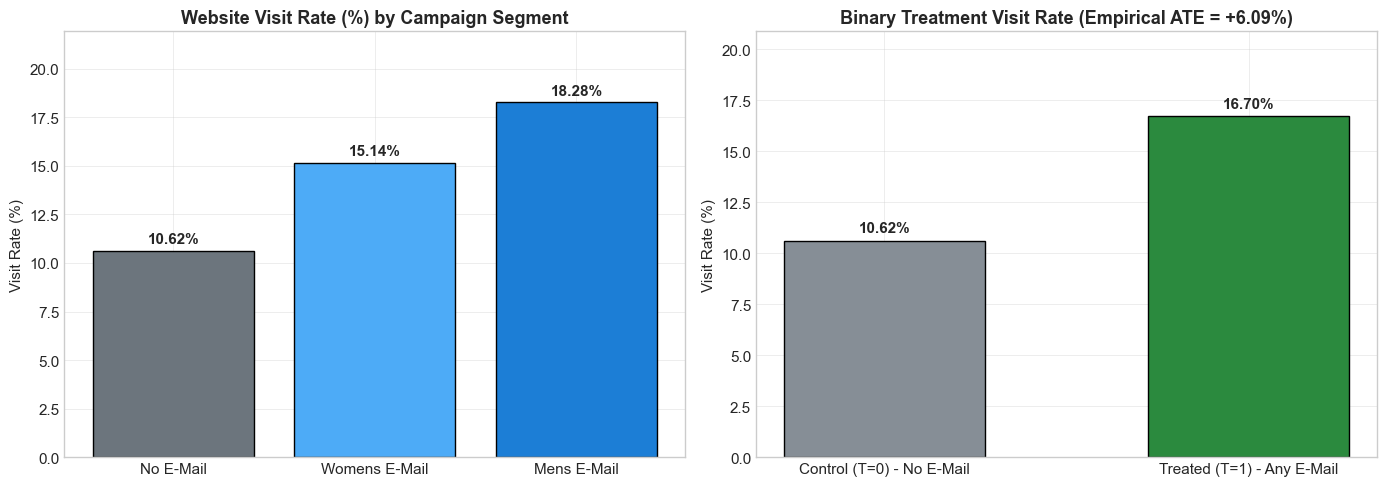

In [6]:
# Summarize outcomes across original campaign arms and binary Treatment vs. Control
segment_summary = (
    df_raw.groupby("segment")[["visit", "conversion", "spend"]]
    .agg(["count", "mean"])
)
print("=== Summary by Original Campaign Segment ===")
print(segment_summary.round(4))

binary_summary = (
    df_raw.groupby("treatment")[["visit", "conversion", "spend"]]
    .agg(["count", "mean"])
)
print("=== Summary by Binary Treatment (0 = No E-Mail, 1 = Any E-Mail) ===")
print(binary_summary.round(4))

visit_control = df_raw.loc[df_raw["treatment"] == 0, "visit"].mean()
visit_treated = df_raw.loc[df_raw["treatment"] == 1, "visit"].mean()
ate_visit = visit_treated - visit_control
print(
    f"Empirical Average Treatment Effect (ATE) on 'visit': "
    f"{visit_treated:.4%} (Treated) - {visit_control:.4%} (Control) = +{ate_visit:.4%}"
)

# Visualize baseline response rates by campaign segment and binary treatment
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

seg_means = df_raw.groupby("segment")["visit"].mean().reindex(["No E-Mail", "Womens E-Mail", "Mens E-Mail"]) * 100
bars1 = axes[0].bar(seg_means.index, seg_means.values, color=["#6c757d", "#4dabf7", "#1c7ed6"], edgecolor="black")
axes[0].set_title("Website Visit Rate (%) by Campaign Segment", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Visit Rate (%)")
axes[0].set_ylim(0, max(seg_means.values) * 1.2)
for bar in bars1:
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4, f"{bar.get_height():.2f}%", ha="center", fontweight="bold")

treat_means = df_raw.groupby("treatment")["visit"].mean() * 100
bars2 = axes[1].bar(["Control (T=0) - No E-Mail", "Treated (T=1) - Any E-Mail"], treat_means.values, color=["#868e96", "#2b8a3e"], edgecolor="black", width=0.55)
axes[1].set_title(f"Binary Treatment Visit Rate (Empirical ATE = +{ate_visit*100:.2f}%)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Visit Rate (%)")
axes[1].set_ylim(0, max(treat_means.values) * 1.25)
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4, f"{bar.get_height():.2f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

In [7]:
def prepare_uplift_data(df: pd.DataFrame, target_col: str = "visit", test_size: float = 0.3, random_state: int = SEED):
    """
    Encode categorical covariates and perform a stratified Train/Test split
    that preserves both treatment assignment (T) and target outcome (Y) proportions.
    """
    feature_cols = ["recency", "history_segment", "history", "mens", "womens", "zip_code", "newbie", "channel"]
    X_df = pd.get_dummies(df[feature_cols], columns=["history_segment", "zip_code", "channel"], drop_first=False, dtype=float)
    # Clean feature names for tree/XGBoost compatibility
    X_df.columns = [
        c.replace(" ", "_").replace(")", "").replace("$", "").replace("-", "_")
        for c in X_df.columns
    ]

    T = df["treatment"].values.astype(int)
    Y = df[target_col].values.astype(int)

    # Stratify jointly on (treatment, target) so both sets have identical ATE and class balance
    strat_key = T * 2 + Y
    X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
        X_df, T, Y, test_size=test_size, random_state=random_state, stratify=strat_key
    )

    return X_train, X_test, T_train, T_test, Y_train, Y_test


X_train, X_test, T_train, T_test, Y_train, Y_test = prepare_uplift_data(df_raw, target_col="visit")

print(f"Encoded Feature Matrix shape : {X_train.shape[1]} features")
print(f"Training set                 : {len(X_train):,} samples (Treated ratio = {T_train.mean():.4f}, Visit rate = {Y_train.mean():.4f})")
print(f"Testing set                  : {len(X_test):,} samples (Treated ratio = {T_test.mean():.4f}, Visit rate = {Y_test.mean():.4f})")
print(
    f"Test Set Empirical ATE       : "
    f"{Y_test[T_test == 1].mean() - Y_test[T_test == 0].mean():+.4%}"
)

Encoded Feature Matrix shape : 18 features
Training set                 : 44,800 samples (Treated ratio = 0.6671, Visit rate = 0.1468)
Testing set                  : 19,200 samples (Treated ratio = 0.6671, Visit rate = 0.1468)
Test Set Empirical ATE       : +6.0983%


## 1.3. Train & evaluate Propensity Models

In [8]:
# 1. Treatment Assignment Propensity Score Model: e(x) = P(T = 1 | X = x)
# Checks covariate balance / common support and provides propensity weights for X-Learner
treatment_propensity_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=SEED)
)
treatment_propensity_model.fit(X_train, T_train)
e_hat_test = treatment_propensity_model.predict_proba(X_test)[:, 1]
e_auc = roc_auc_score(T_test, e_hat_test)
print(f"Treatment Assignment Propensity e(x) ROC-AUC: {e_auc:.4f} ( ~0.50 confirms randomized assignment! )")
print(f"Estimated e(x) range on test set            : [{e_hat_test.min():.4f}, {e_hat_test.max():.4f}], mean = {e_hat_test.mean():.4f}")
print("-" * 80)

# 2. Outcome (Visit) Propensity Models: p(x) = P(Y = 1 | X = x)
propensity_models = {
    "Propensity (LogReg)": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=SEED)
    ),
    "Propensity (XGBoost)": XGBClassifier(
        n_estimators=120,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=-1
    ),
}

propensity_preds = {}
propensity_metrics = []

for name, model in propensity_models.items():
    model.fit(X_train, Y_train)
    probs = model.predict_proba(X_test)[:, 1]
    propensity_preds[name] = probs

    roc_auc = roc_auc_score(Y_test, probs)
    pr_auc = average_precision_score(Y_test, probs)
    brier = brier_score_loss(Y_test, probs)
    propensity_metrics.append({
        "Model": name,
        "ROC-AUC": round(roc_auc, 4),
        "PR-AUC": round(pr_auc, 4),
        "Brier Score (lower is better)": round(brier, 4),
        "Mean Pred Prob": round(float(probs.mean()), 4),
    })

propensity_metrics_df = pd.DataFrame(propensity_metrics)
print("=== Outcome Propensity Models Evaluation on Test Set ===")
print(propensity_metrics_df.to_string(index=False))

Treatment Assignment Propensity e(x) ROC-AUC: 0.4965 ( ~0.50 confirms randomized assignment! )
Estimated e(x) range on test set            : [0.6437, 0.7356], mean = 0.6670
--------------------------------------------------------------------------------
=== Outcome Propensity Models Evaluation on Test Set ===
               Model  ROC-AUC  PR-AUC  Brier Score (lower is better)  Mean Pred Prob
 Propensity (LogReg)   0.6344  0.2179                         0.1219          0.1467
Propensity (XGBoost)   0.6280  0.2139                         0.1221          0.1466


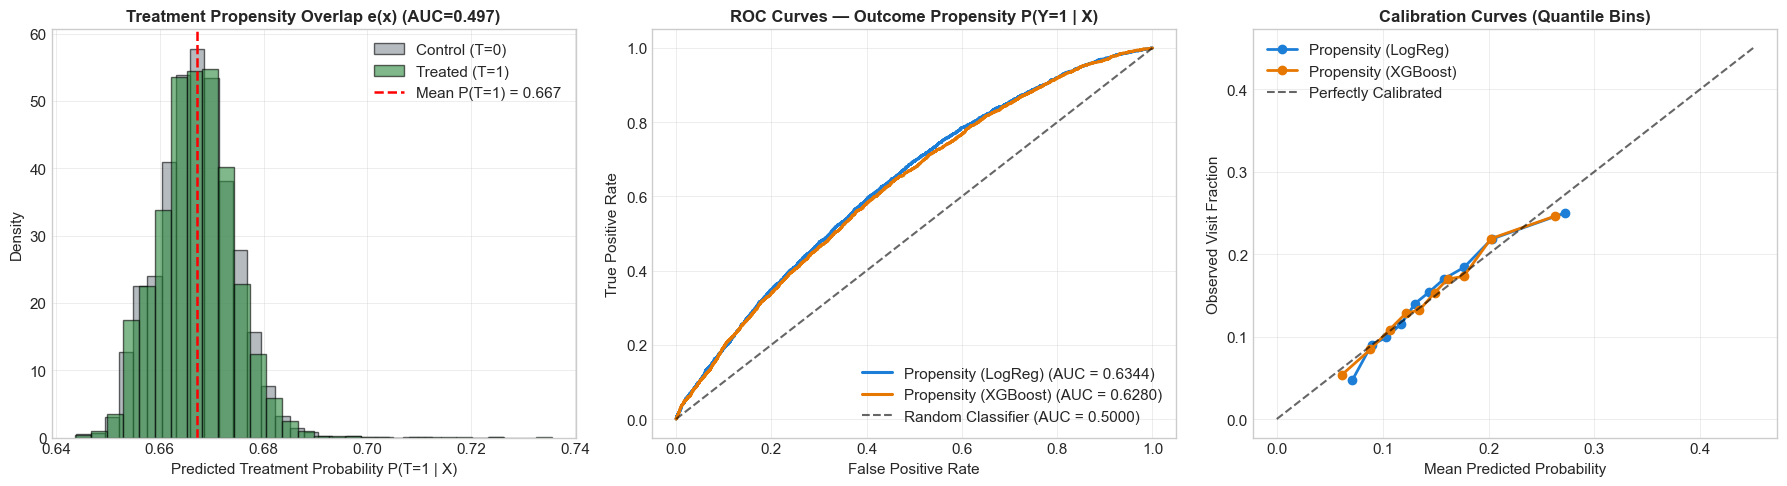

In [9]:
# Plot Treatment Propensity Overlap, ROC Curves, and Probability Calibration Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Treatment Propensity Score Overlap e(x) = P(T=1 | X)
axes[0].hist(e_hat_test[T_test == 0], bins=30, alpha=0.6, density=True, label="Control (T=0)", color="#868e96", edgecolor="black")
axes[0].hist(e_hat_test[T_test == 1], bins=30, alpha=0.6, density=True, label="Treated (T=1)", color="#2b8a3e", edgecolor="black")
axes[0].axvline(T_test.mean(), color="red", linestyle="--", linewidth=1.8, label=f"Mean P(T=1) = {T_test.mean():.3f}")
axes[0].set_title(f"Treatment Propensity Overlap e(x) (AUC={e_auc:.3f})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Predicted Treatment Probability P(T=1 | X)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Panel 2: ROC Curves for Outcome Propensity Models
colors = {"Propensity (LogReg)": "#1c7ed6", "Propensity (XGBoost)": "#e67700"}
for name, probs in propensity_preds.items():
    fpr, tpr, _ = roc_curve(Y_test, probs)
    auc_val = roc_auc_score(Y_test, probs)
    axes[1].plot(fpr, tpr, linewidth=2.2, color=colors[name], label=f"{name} (AUC = {auc_val:.4f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Classifier (AUC = 0.5000)")
axes[1].set_title("ROC Curves — Outcome Propensity P(Y=1 | X)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")

# Panel 3: Calibration (Reliability) Curves
for name, probs in propensity_preds.items():
    frac_pos, mean_pred = calibration_curve(Y_test, probs, n_bins=10, strategy="quantile")
    axes[2].plot(mean_pred, frac_pos, "o-", linewidth=2, color=colors[name], label=name)
axes[2].plot([0, 0.45], [0, 0.45], "k--", alpha=0.6, label="Perfectly Calibrated")
axes[2].set_title("Calibration Curves (Quantile Bins)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Mean Predicted Probability")
axes[2].set_ylabel("Observed Visit Fraction")
axes[2].legend(loc="upper left")

plt.tight_layout()
plt.show()

## 1.4. Deciles Lift Plot for Propensity Models

In [10]:
def compute_propensity_deciles(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10) -> pd.DataFrame:
    """
    Partition test samples into n_bins deciles ordered from highest predicted score (Decile 1)
    to lowest predicted score (Decile 10), and compute conversion rate, decile lift, and cumulative lift.
    """
    order = np.argsort(-y_prob, kind="mergesort")
    y_sorted = y_true[order]
    p_sorted = y_prob[order]

    overall_rate = y_true.mean()
    total_positives = y_true.sum()

    indices_splits = np.array_split(np.arange(len(y_true)), n_bins)
    rows = []
    cum_positives = 0
    cum_count = 0

    for idx, bucket in enumerate(indices_splits, start=1):
        y_bin = y_sorted[bucket]
        p_bin = p_sorted[bucket]
        n_obs = len(y_bin)
        n_pos = int(y_bin.sum())
        resp_rate = y_bin.mean()
        lift = resp_rate / overall_rate if overall_rate > 0 else 0.0

        cum_positives += n_pos
        cum_count += n_obs
        cum_rate = cum_positives / cum_count
        cum_lift = cum_rate / overall_rate if overall_rate > 0 else 0.0
        cum_gain_pct = (cum_positives / total_positives) * 100.0 if total_positives > 0 else 0.0

        rows.append({
            "Decile": f"D{idx}",
            "Decile_Num": idx,
            "Samples": n_obs,
            "Positives": n_pos,
            "Mean_Pred_Prob": round(float(p_bin.mean()), 4),
            "Observed_Rate": round(float(resp_rate), 4),
            "Decile_Lift": round(float(lift), 4),
            "Cumulative_Lift": round(float(cum_lift), 4),
            "Cumulative_Gain_%": round(float(cum_gain_pct), 2),
        })

    return pd.DataFrame(rows)


propensity_deciles = {
    name: compute_propensity_deciles(Y_test, probs, n_bins=10)
    for name, probs in propensity_preds.items()
}

print("=== Deciles Lift Table: Propensity (XGBoost) ===")
print(propensity_deciles["Propensity (XGBoost)"].to_string(index=False))

=== Deciles Lift Table: Propensity (XGBoost) ===
Decile  Decile_Num  Samples  Positives  Mean_Pred_Prob  Observed_Rate  Decile_Lift  Cumulative_Lift  Cumulative_Gain_%
    D1           1     1920        473          0.2632         0.2464       1.6785           1.6785              16.78
    D2           2     1920        420          0.2023         0.2188       1.4904           1.5845              31.69
    D3           3     1920        332          0.1765         0.1729       1.1781           1.4490              43.47
    D4           4     1920        326          0.1615         0.1698       1.1568           1.3760              55.04
    D5           5     1920        294          0.1491         0.1531       1.0433           1.3094              65.47
    D6           6     1920        254          0.1348         0.1323       0.9013           1.2414              74.49
    D7           7     1920        246          0.1218         0.1281       0.8730           1.1888              83.22

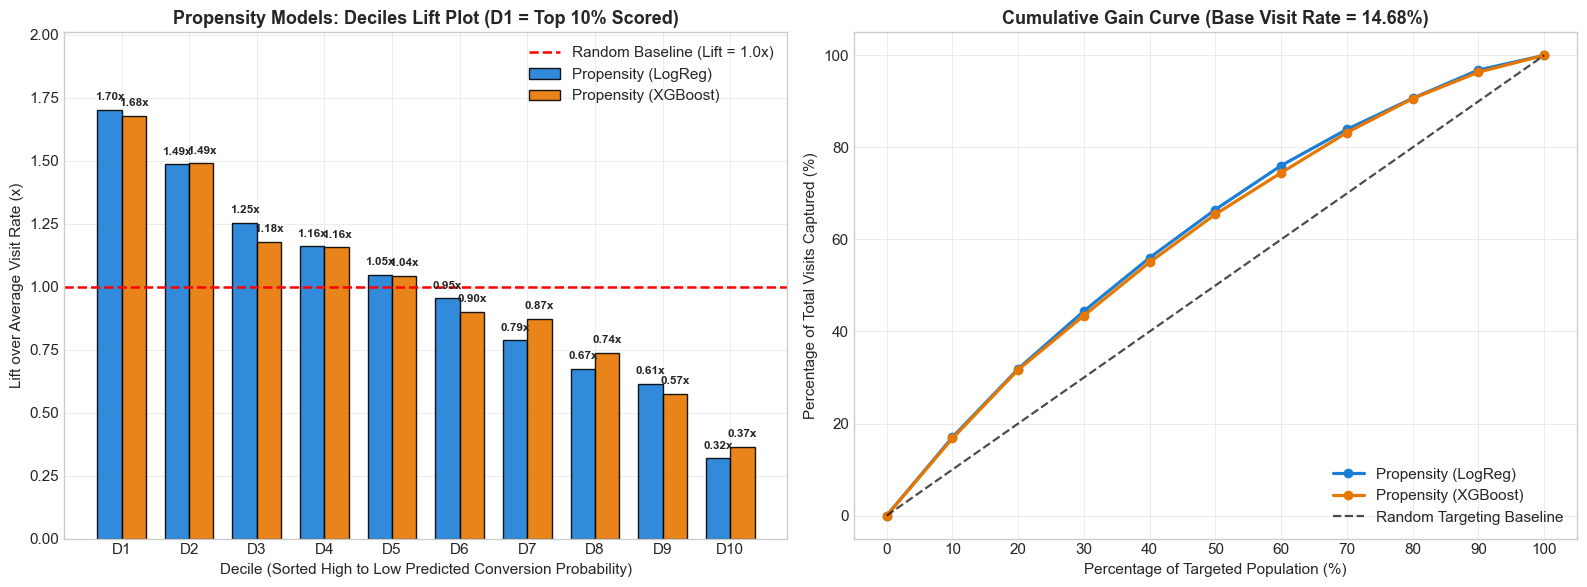

In [11]:
def plot_propensity_deciles_lift(deciles_dict: dict, overall_rate: float):
    """
    Visualize Deciles Lift Bar Chart and Cumulative Gain / Lift Curves for Propensity Models.
    """
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    decile_labels = [f"D{i}" for i in range(1, 11)]
    x = np.arange(len(decile_labels))
    width = 0.36
    palette = ["#1c7ed6", "#e67700"]

    # Left Subplot: Decile Lift by Decile (D1 = Top 10% highest propensity)
    for i, (name, df_dec) in enumerate(deciles_dict.items()):
        offset = (i - (len(deciles_dict) - 1) / 2) * width
        bars = axes[0].bar(
            x + offset,
            df_dec["Decile_Lift"],
            width=width,
            label=name,
            color=palette[i % len(palette)],
            edgecolor="black",
            alpha=0.9
        )
        for bar in bars:
            h = bar.get_height()
            axes[0].text(
                bar.get_x() + bar.get_width() / 2,
                h + 0.03,
                f"{h:.2f}x",
                ha="center",
                va="bottom",
                fontsize=8.5,
                fontweight="bold"
            )

    axes[0].axhline(1.0, color="red", linestyle="--", linewidth=1.8, label="Random Baseline (Lift = 1.0x)")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(decile_labels)
    axes[0].set_ylim(0, max(df["Decile_Lift"].max() for df in deciles_dict.values()) * 1.18)
    axes[0].set_title("Propensity Models: Deciles Lift Plot (D1 = Top 10% Scored)", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("Decile (Sorted High to Low Predicted Conversion Probability)")
    axes[0].set_ylabel("Lift over Average Visit Rate (x)")
    axes[0].legend(loc="upper right")

    # Right Subplot: Cumulative Gain (%) & Cumulative Lift across Deciles
    pct_pop = np.arange(0, 101, 10)
    for i, (name, df_dec) in enumerate(deciles_dict.items()):
        gains = np.concatenate([[0.0], df_dec["Cumulative_Gain_%"].values])
        axes[1].plot(pct_pop, gains, "o-", linewidth=2.3, color=palette[i % len(palette)], label=name)

    axes[1].plot([0, 100], [0, 100], "k--", linewidth=1.6, alpha=0.7, label="Random Targeting Baseline")
    axes[1].set_title(f"Cumulative Gain Curve (Base Visit Rate = {overall_rate*100:.2f}%)", fontsize=13, fontweight="bold")
    axes[1].set_xlabel("Percentage of Targeted Population (%)")
    axes[1].set_ylabel("Percentage of Total Visits Captured (%)")
    axes[1].set_xticks(pct_pop)
    axes[1].legend(loc="lower right")

    plt.tight_layout()
    plt.show()


plot_propensity_deciles_lift(propensity_deciles, overall_rate=Y_test.mean())

# Part II: Uplift Modeling (Causal Modeling: S-Learner, T-Learner, X-Learner)

## 2.1. S-Learner (Single-Model Uplift Estimator)

In [12]:
class SLearner:
    """
    S-Learner (Single-Model Meta-Learner):
    Appends the binary treatment indicator T as an input feature to X, trains a single
    supervised estimator, and predicts CATE as:
        tau_S(x) = P(Y=1 | X=x, T=1) - P(Y=1 | X=x, T=0)
    """

    def __init__(self, base_estimator):
        self.base_estimator = base_estimator
        self.model_ = None

    def fit(self, X: pd.DataFrame, T: np.ndarray, Y: np.ndarray):
        self.model_ = clone(self.base_estimator)
        X_aug = X.copy()
        X_aug["treatment_indicator"] = T
        self.model_.fit(X_aug, Y)
        return self

    def predict_uplift(self, X: pd.DataFrame) -> np.ndarray:
        X_treated = X.copy()
        X_treated["treatment_indicator"] = 1
        X_control = X.copy()
        X_control["treatment_indicator"] = 0

        p_treated = self.model_.predict_proba(X_treated)[:, 1]
        p_control = self.model_.predict_proba(X_control)[:, 1]
        return p_treated - p_control


base_clf = GradientBoostingClassifier(
    n_estimators=80,
    max_depth=3,
    min_samples_leaf=100,
    learning_rate=0.05,
    random_state=SEED
)

s_learner = SLearner(base_estimator=base_clf).fit(X_train, T_train, Y_train)
uplift_s_test = s_learner.predict_uplift(X_test)

print("=== S-Learner (Single-Model) Test Predictions ===")
print(f"Predicted Uplift Mean : {uplift_s_test.mean():+.4%} (True Test ATE = {Y_test[T_test==1].mean() - Y_test[T_test==0].mean():+.4%})")
print(f"Predicted Uplift Std  : {uplift_s_test.std():.4%}")
print(f"Predicted Uplift Range: [{uplift_s_test.min():+.4%}, {uplift_s_test.max():+.4%}]")

=== S-Learner (Single-Model) Test Predictions ===
Predicted Uplift Mean : +5.1173% (True Test ATE = +6.0983%)
Predicted Uplift Std  : 2.4886%
Predicted Uplift Range: [-1.6843%, +14.5626%]


## 2.2. T-Learner (Two-Model Uplift Estimator)

In [13]:
class TLearner:
    """
    T-Learner (Two-Model Meta-Learner):
    Fits two independent estimators:
      - mu_0(x) = E[Y | X=x, T=0] on Control units
      - mu_1(x) = E[Y | X=x, T=1] on Treated units
    Predicts CATE as:
        tau_T(x) = mu_1(x) - mu_0(x)
    """

    def __init__(self, base_estimator):
        self.base_estimator = base_estimator
        self.model_0_ = None
        self.model_1_ = None

    def fit(self, X: pd.DataFrame, T: np.ndarray, Y: np.ndarray):
        self.model_0_ = clone(self.base_estimator).fit(X[T == 0], Y[T == 0])
        self.model_1_ = clone(self.base_estimator).fit(X[T == 1], Y[T == 1])
        return self

    def predict_uplift(self, X: pd.DataFrame) -> np.ndarray:
        p_treated = self.model_1_.predict_proba(X)[:, 1]
        p_control = self.model_0_.predict_proba(X)[:, 1]
        return p_treated - p_control


t_learner = TLearner(base_estimator=base_clf).fit(X_train, T_train, Y_train)
uplift_t_test = t_learner.predict_uplift(X_test)

print("=== T-Learner (Two-Model) Test Predictions ===")
print(f"Predicted Uplift Mean : {uplift_t_test.mean():+.4%} (True Test ATE = {Y_test[T_test==1].mean() - Y_test[T_test==0].mean():+.4%})")
print(f"Predicted Uplift Std  : {uplift_t_test.std():.4%}")
print(f"Predicted Uplift Range: [{uplift_t_test.min():+.4%}, {uplift_t_test.max():+.4%}]")

=== T-Learner (Two-Model) Test Predictions ===
Predicted Uplift Mean : +6.0285% (True Test ATE = +6.0983%)
Predicted Uplift Std  : 2.6595%
Predicted Uplift Range: [-7.4520%, +22.5254%]


## 2.3. X-Learner (Cross-Model Uplift Estimator with Propensity Weighting)

In [14]:
class XLearner:
    """
    X-Learner (Künzel et al., 2019):
    Stage 1: Fit outcome models mu_0(x) on T=0 and mu_1(x) on T=1.
    Stage 2: Impute counterfactual treatment effects:
               D_1 = Y_1 - mu_0(X_1)   for Treated units (T=1)
               D_0 = mu_1(X_0) - Y_0   for Control units (T=0)
             Fit second-stage regressors tau_1(x) on (X_1, D_1) and tau_0(x) on (X_0, D_0).
    Stage 3: Combine using treatment propensity score e(x) = P(T=1 | X=x):
               tau_X(x) = e(x) * tau_0(x) + (1 - e(x)) * tau_1(x)
    """

    def __init__(self, outcome_estimator, effect_regressor, propensity_estimator=None):
        self.outcome_estimator = outcome_estimator
        self.effect_regressor = effect_regressor
        self.propensity_estimator = propensity_estimator
        self.mu_0_ = None
        self.mu_1_ = None
        self.tau_0_ = None
        self.tau_1_ = None
        self.prop_model_ = None

    def fit(self, X: pd.DataFrame, T: np.ndarray, Y: np.ndarray):
        # Stage 1: Outcome response models
        self.mu_0_ = clone(self.outcome_estimator).fit(X[T == 0], Y[T == 0])
        self.mu_1_ = clone(self.outcome_estimator).fit(X[T == 1], Y[T == 1])

        # Stage 2: Imputed individual treatment effects & CATE regressors
        d_1 = Y[T == 1] - self.mu_0_.predict_proba(X[T == 1])[:, 1]
        d_0 = self.mu_1_.predict_proba(X[T == 0])[:, 1] - Y[T == 0]

        self.tau_1_ = clone(self.effect_regressor).fit(X[T == 1], d_1)
        self.tau_0_ = clone(self.effect_regressor).fit(X[T == 0], d_0)

        # Stage 3: Propensity score model e(x) = P(T=1 | X=x)
        if self.propensity_estimator is not None:
            self.prop_model_ = clone(self.propensity_estimator).fit(X, T)
        else:
            self.prop_model_ = make_pipeline(
                StandardScaler(),
                LogisticRegression(max_iter=1000, random_state=SEED)
            ).fit(X, T)
        return self

    def predict_uplift(self, X: pd.DataFrame) -> np.ndarray:
        e_x = self.prop_model_.predict_proba(X)[:, 1]
        tau_1_pred = self.tau_1_.predict(X)
        tau_0_pred = self.tau_0_.predict(X)
        return e_x * tau_0_pred + (1.0 - e_x) * tau_1_pred


base_reg = GradientBoostingRegressor(
    n_estimators=80,
    max_depth=3,
    min_samples_leaf=100,
    learning_rate=0.05,
    random_state=SEED
)

x_learner = XLearner(
    outcome_estimator=base_clf,
    effect_regressor=base_reg,
    propensity_estimator=treatment_propensity_model
).fit(X_train, T_train, Y_train)

uplift_x_test = x_learner.predict_uplift(X_test)

print("=== X-Learner (Cross-Model) Test Predictions ===")
print(f"Predicted Uplift Mean : {uplift_x_test.mean():+.4%} (True Test ATE = {Y_test[T_test==1].mean() - Y_test[T_test==0].mean():+.4%})")
print(f"Predicted Uplift Std  : {uplift_x_test.std():.4%}")
print(f"Predicted Uplift Range: [{uplift_x_test.min():+.4%}, {uplift_x_test.max():+.4%}]")

=== X-Learner (Cross-Model) Test Predictions ===
Predicted Uplift Mean : +6.0295% (True Test ATE = +6.0983%)
Predicted Uplift Std  : 1.8167%
Predicted Uplift Range: [-1.5721%, +12.7507%]


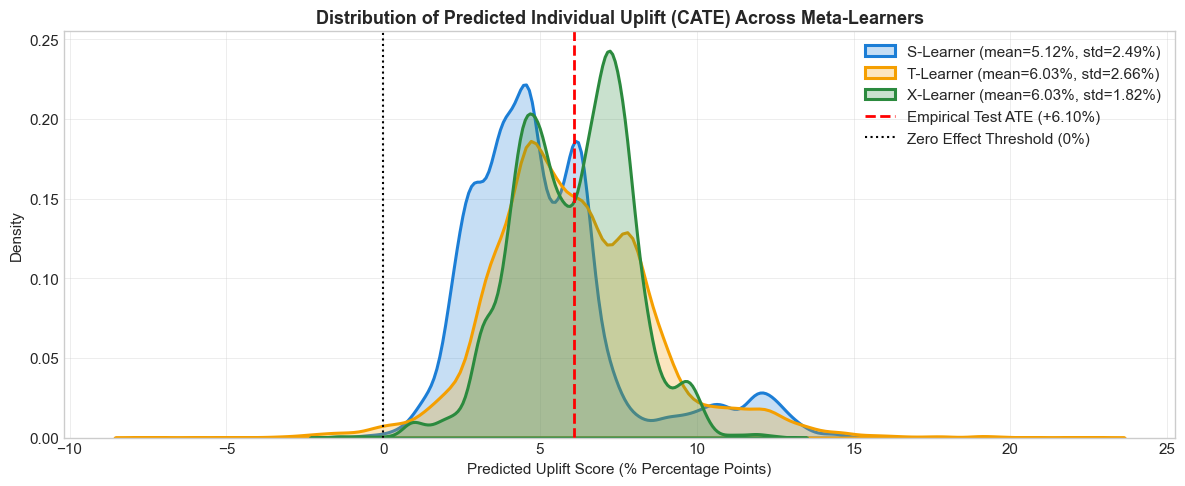

In [15]:
# Visualize Predicted Uplift (CATE) Distributions for S-Learner, T-Learner, and X-Learner
fig, ax = plt.subplots(figsize=(12, 5))

true_ate_test = (Y_test[T_test == 1].mean() - Y_test[T_test == 0].mean()) * 100

sns.kdeplot(uplift_s_test * 100, fill=True, alpha=0.25, linewidth=2.2, color="#1c7ed6", label=f"S-Learner (mean={uplift_s_test.mean()*100:.2f}%, std={uplift_s_test.std()*100:.2f}%)", ax=ax)
sns.kdeplot(uplift_t_test * 100, fill=True, alpha=0.25, linewidth=2.2, color="#f59f00", label=f"T-Learner (mean={uplift_t_test.mean()*100:.2f}%, std={uplift_t_test.std()*100:.2f}%)", ax=ax)
sns.kdeplot(uplift_x_test * 100, fill=True, alpha=0.25, linewidth=2.2, color="#2b8a3e", label=f"X-Learner (mean={uplift_x_test.mean()*100:.2f}%, std={uplift_x_test.std()*100:.2f}%)", ax=ax)

ax.axvline(true_ate_test, color="red", linestyle="--", linewidth=2, label=f"Empirical Test ATE (+{true_ate_test:.2f}%)")
ax.axvline(0.0, color="black", linestyle=":", linewidth=1.5, label="Zero Effect Threshold (0%)")
ax.set_title("Distribution of Predicted Individual Uplift (CATE) Across Meta-Learners", fontsize=13, fontweight="bold")
ax.set_xlabel("Predicted Uplift Score (% Percentage Points)")
ax.set_ylabel("Density")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 2.4. Deciles Uplift / Lift Plot & Multi-Model Causal Evaluation

In [16]:
def compute_uplift_deciles(
    y_true: np.ndarray,
    treatment: np.ndarray,
    score: np.ndarray,
    n_bins: int = 10
) -> pd.DataFrame:
    """
    Sort test instances in descending order of predicted uplift/propensity score,
    partition into 10 equal-sized deciles (D1 = Top 10% highest score, D10 = Bottom 10%),
    and compute per-decile Treated/Control response rates, Net Uplift, and Uplift Lift over ATE.
    """
    order = np.argsort(-score, kind="mergesort")
    y_s = y_true[order]
    t_s = treatment[order]
    s_s = score[order]

    overall_ate = y_true[treatment == 1].mean() - y_true[treatment == 0].mean()
    buckets = np.array_split(np.arange(len(y_true)), n_bins)

    rows = []
    for idx, b in enumerate(buckets, start=1):
        yb = y_s[b]
        tb = t_s[b]
        sb = s_s[b]

        n_t1 = int((tb == 1).sum())
        n_t0 = int((tb == 0).sum())
        rate_t1 = float(yb[tb == 1].mean()) if n_t1 > 0 else 0.0
        rate_t0 = float(yb[tb == 0].mean()) if n_t0 > 0 else 0.0
        obs_uplift = rate_t1 - rate_t0
        uplift_lift = obs_uplift / overall_ate if overall_ate != 0 else 0.0

        rows.append({
            "Decile": f"D{idx}",
            "Decile_Num": idx,
            "N_Treated": n_t1,
            "N_Control": n_t0,
            "Treated_Rate_%": round(rate_t1 * 100, 2),
            "Control_Rate_%": round(rate_t0 * 100, 2),
            "Observed_Uplift_%": round(obs_uplift * 100, 2),
            "Uplift_Lift_x": round(uplift_lift, 3),
            "Mean_Pred_Score": round(float(sb.mean()), 4),
        })

    return pd.DataFrame(rows)


def compute_uplift_and_qini_curves(y_true: np.ndarray, treatment: np.ndarray, score: np.ndarray):
    """
    Compute cumulative Uplift curve, Qini curve, AUUC, and Qini coefficient.
    """
    order = np.argsort(-score, kind="mergesort")
    y_s = y_true[order]
    t_s = treatment[order]

    cum_t1 = np.cumsum(t_s == 1)
    cum_t0 = np.cumsum(t_s == 0)
    cum_y1 = np.cumsum((y_s == 1) & (t_s == 1))
    cum_y0 = np.cumsum((y_s == 1) & (t_s == 0))

    # Avoid division by zero at the very first elements
    rate_t1 = np.where(cum_t1 > 0, cum_y1 / np.maximum(cum_t1, 1), 0.0)
    rate_t0 = np.where(cum_t0 > 0, cum_y0 / np.maximum(cum_t0, 1), 0.0)

    n_total = len(y_true)
    pop_frac = np.arange(1, n_total + 1) / n_total

    # Cumulative incremental conversions (Uplift gain curve) as fraction of total population
    uplift_curve = (rate_t1 - rate_t0) * pop_frac
    # Qini curve: incremental responses scaled by treated count
    qini_curve = (cum_y1 - cum_y0 * np.where(cum_t0 > 0, cum_t1 / np.maximum(cum_t0, 1), 0.0)) / n_total

    random_uplift_line = pop_frac * uplift_curve[-1]
    random_qini_line = pop_frac * qini_curve[-1]

    auuc = float(np.trapz(uplift_curve - random_uplift_line, pop_frac))
    qini_coef = float(np.trapz(qini_curve - random_qini_line, pop_frac))

    return {
        "pop_frac": np.concatenate([[0.0], pop_frac]),
        "uplift_curve": np.concatenate([[0.0], uplift_curve]),
        "qini_curve": np.concatenate([[0.0], qini_curve]),
        "random_uplift": np.concatenate([[0.0], random_uplift_line]),
        "random_qini": np.concatenate([[0.0], random_qini_line]),
        "auuc": auuc,
        "qini_coef": qini_coef,
    }


all_model_scores = {
    "Propensity (XGBoost)": propensity_preds["Propensity (XGBoost)"],
    "S-Learner": uplift_s_test,
    "T-Learner": uplift_t_test,
    "X-Learner": uplift_x_test,
}

uplift_deciles_dict = {
    name: compute_uplift_deciles(Y_test, T_test, scores, n_bins=10)
    for name, scores in all_model_scores.items()
}

curves_dict = {
    name: compute_uplift_and_qini_curves(Y_test, T_test, scores)
    for name, scores in all_model_scores.items()
}

# Build summary table across all models
overall_ate_pct = (Y_test[T_test == 1].mean() - Y_test[T_test == 0].mean()) * 100
summary_rows = []
for name, df_d in uplift_deciles_dict.items():
    d1_uplift = df_d.loc[df_d["Decile_Num"] == 1, "Observed_Uplift_%"].values[0]
    top3_uplift = df_d.loc[df_d["Decile_Num"] <= 3, "Observed_Uplift_%"].mean()
    bot3_uplift = df_d.loc[df_d["Decile_Num"] >= 8, "Observed_Uplift_%"].mean()
    summary_rows.append({
        "Model": name,
        "D1 (Top 10%) Uplift (%)": round(d1_uplift, 2),
        "Top 30% (D1-D3) Uplift (%)": round(top3_uplift, 2),
        "Bottom 30% (D8-D10) Uplift (%)": round(bot3_uplift, 2),
        "Top 30% Lift over ATE (x)": round(top3_uplift / overall_ate_pct, 3),
        "AUUC (net over random)": round(curves_dict[name]["auuc"], 5),
        "Qini Coef": round(curves_dict[name]["qini_coef"], 5),
    })

comparison_df = pd.DataFrame(summary_rows)
print("=== Causal & Uplift Evaluation Summary on Test Set ===")
print(comparison_df.to_string(index=False))
print("-" * 95)

# Side-by-side Decile Uplift (%) Table across all models
decile_matrix = pd.DataFrame({"Decile": [f"D{i}" for i in range(1, 11)]})
for name, df_d in uplift_deciles_dict.items():
    decile_matrix[f"{name} Uplift (%)"] = df_d["Observed_Uplift_%"]
    decile_matrix[f"{name} Lift (x)"] = df_d["Uplift_Lift_x"]

print("=== Decile-by-Decile Observed Uplift (%) and Uplift Lift (x over ATE) ===")
print(decile_matrix.to_string(index=False))

=== Causal & Uplift Evaluation Summary on Test Set ===
               Model  D1 (Top 10%) Uplift (%)  Top 30% (D1-D3) Uplift (%)  Bottom 30% (D8-D10) Uplift (%)  Top 30% Lift over ATE (x)  AUUC (net over random)  Qini Coef
Propensity (XGBoost)                     8.34                        6.53                            5.87                      1.070                 0.00169    0.00103
           S-Learner                    12.73                        8.44                            4.15                      1.384                 0.00508    0.00332
           T-Learner                    12.29                        8.01                            4.26                      1.313                 0.00442    0.00289
           X-Learner                    13.61                        8.92                            4.47                      1.463                 0.00569    0.00379
-----------------------------------------------------------------------------------------------
=== Decil

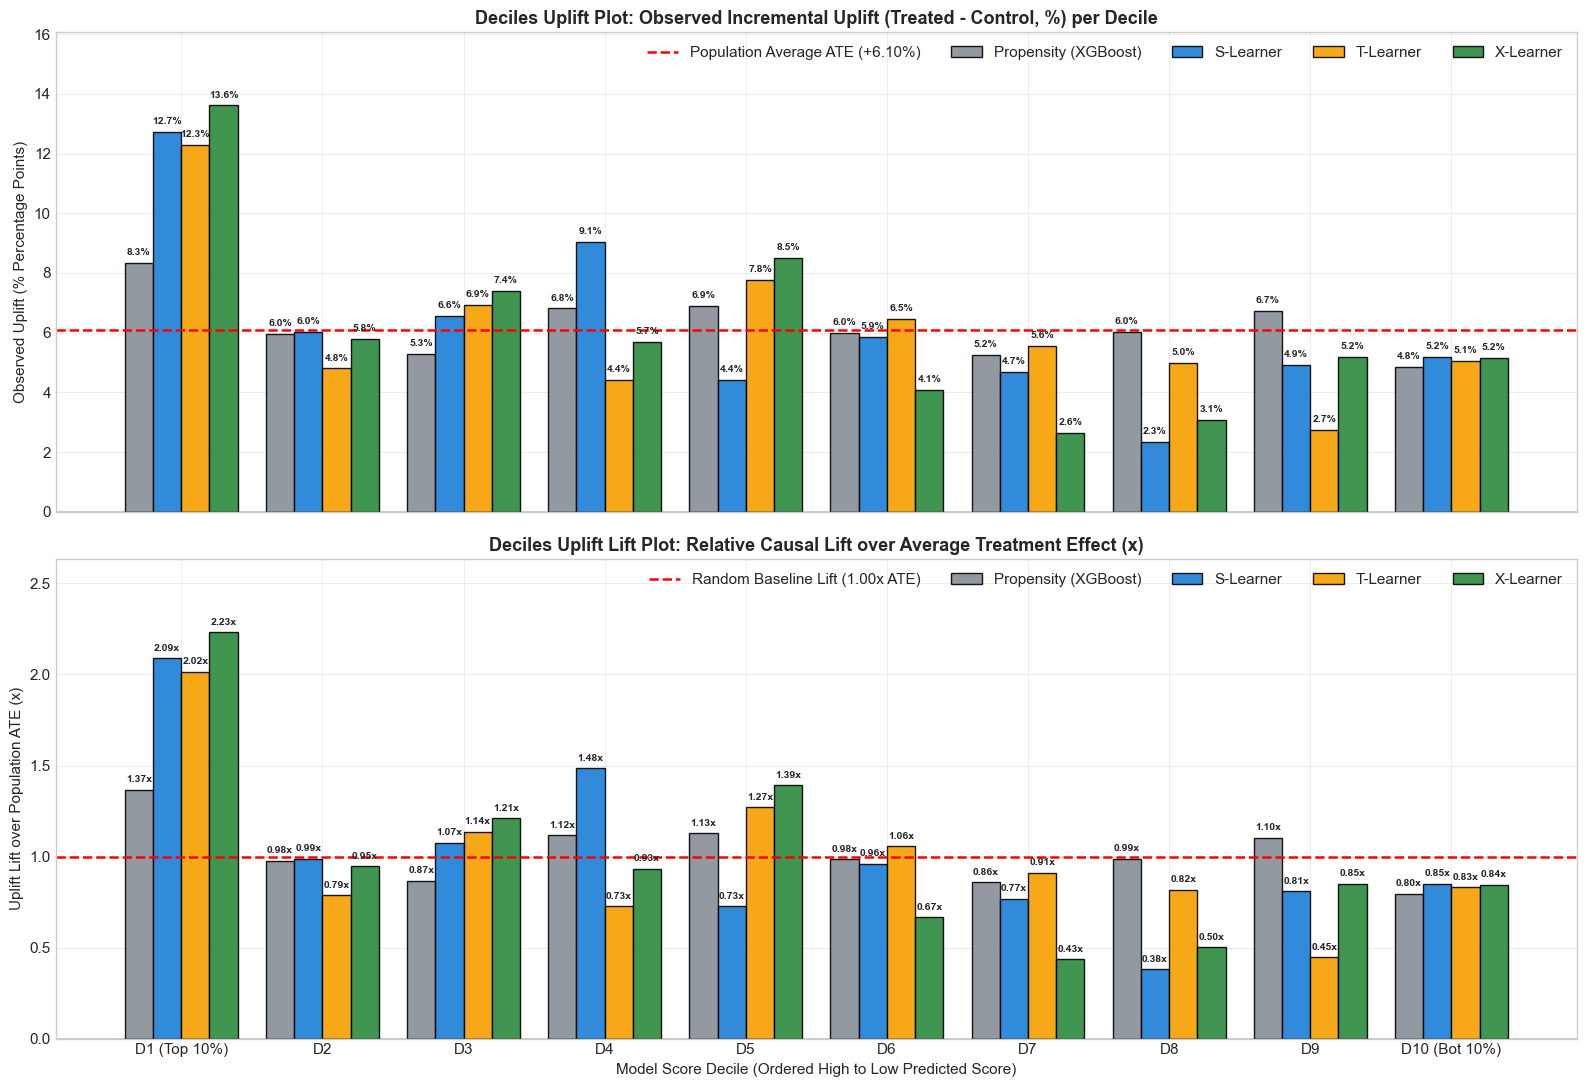

In [17]:
# Plot 1: Multi-Model Deciles Uplift (%) and Deciles Uplift Lift (x) Bar Plots
fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

decile_labels = [f"D{i}" for i in range(1, 11)]
x = np.arange(len(decile_labels))
width = 0.20
model_colors = {
    "Propensity (XGBoost)": "#868e96",
    "S-Learner": "#1c7ed6",
    "T-Learner": "#f59f00",
    "X-Learner": "#2b8a3e",
}

# Top Subplot: Observed Uplift (%) in each Decile (D1 to D10)
for idx, (name, df_d) in enumerate(uplift_deciles_dict.items()):
    offset = (idx - 1.5) * width
    bars = axes[0].bar(
        x + offset,
        df_d["Observed_Uplift_%"],
        width=width,
        color=model_colors[name],
        edgecolor="black",
        alpha=0.9,
        label=name
    )
    for bar in bars:
        h = bar.get_height()
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            h + (0.20 if h >= 0 else -0.55),
            f"{h:.1f}%",
            ha="center",
            va="bottom",
            fontsize=7.5,
            fontweight="bold"
        )

axes[0].axhline(overall_ate_pct, color="red", linestyle="--", linewidth=1.8, label=f"Population Average ATE (+{overall_ate_pct:.2f}%)")
axes[0].axhline(0.0, color="black", linewidth=1.0)
axes[0].set_title("Deciles Uplift Plot: Observed Incremental Uplift (Treated - Control, %) per Decile", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Observed Uplift (% Percentage Points)")
axes[0].set_ylim(0, max(df["Observed_Uplift_%"].max() for df in uplift_deciles_dict.values()) * 1.18)
axes[0].legend(loc="upper right", ncol=5)

# Bottom Subplot: Decile Uplift Lift (Uplift_d / ATE_overall) in each Decile (D1 to D10)
for idx, (name, df_d) in enumerate(uplift_deciles_dict.items()):
    offset = (idx - 1.5) * width
    bars = axes[1].bar(
        x + offset,
        df_d["Uplift_Lift_x"],
        width=width,
        color=model_colors[name],
        edgecolor="black",
        alpha=0.9,
        label=name
    )
    for bar in bars:
        h = bar.get_height()
        axes[1].text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.03,
            f"{h:.2f}x",
            ha="center",
            va="bottom",
            fontsize=7.5,
            fontweight="bold"
        )

axes[1].axhline(1.0, color="red", linestyle="--", linewidth=1.8, label="Random Baseline Lift (1.00x ATE)")
axes[1].axhline(0.0, color="black", linewidth=1.0)
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"D{i} (Top {i*10}%)" if i == 1 else (f"D{i} (Bot 10%)" if i == 10 else f"D{i}") for i in range(1, 11)])
axes[1].set_title("Deciles Uplift Lift Plot: Relative Causal Lift over Average Treatment Effect (x)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Model Score Decile (Ordered High to Low Predicted Score)")
axes[1].set_ylabel("Uplift Lift over Population ATE (x)")
axes[1].set_ylim(0, max(df["Uplift_Lift_x"].max() for df in uplift_deciles_dict.values()) * 1.18)
axes[1].legend(loc="upper right", ncol=5)

plt.tight_layout()
plt.show()

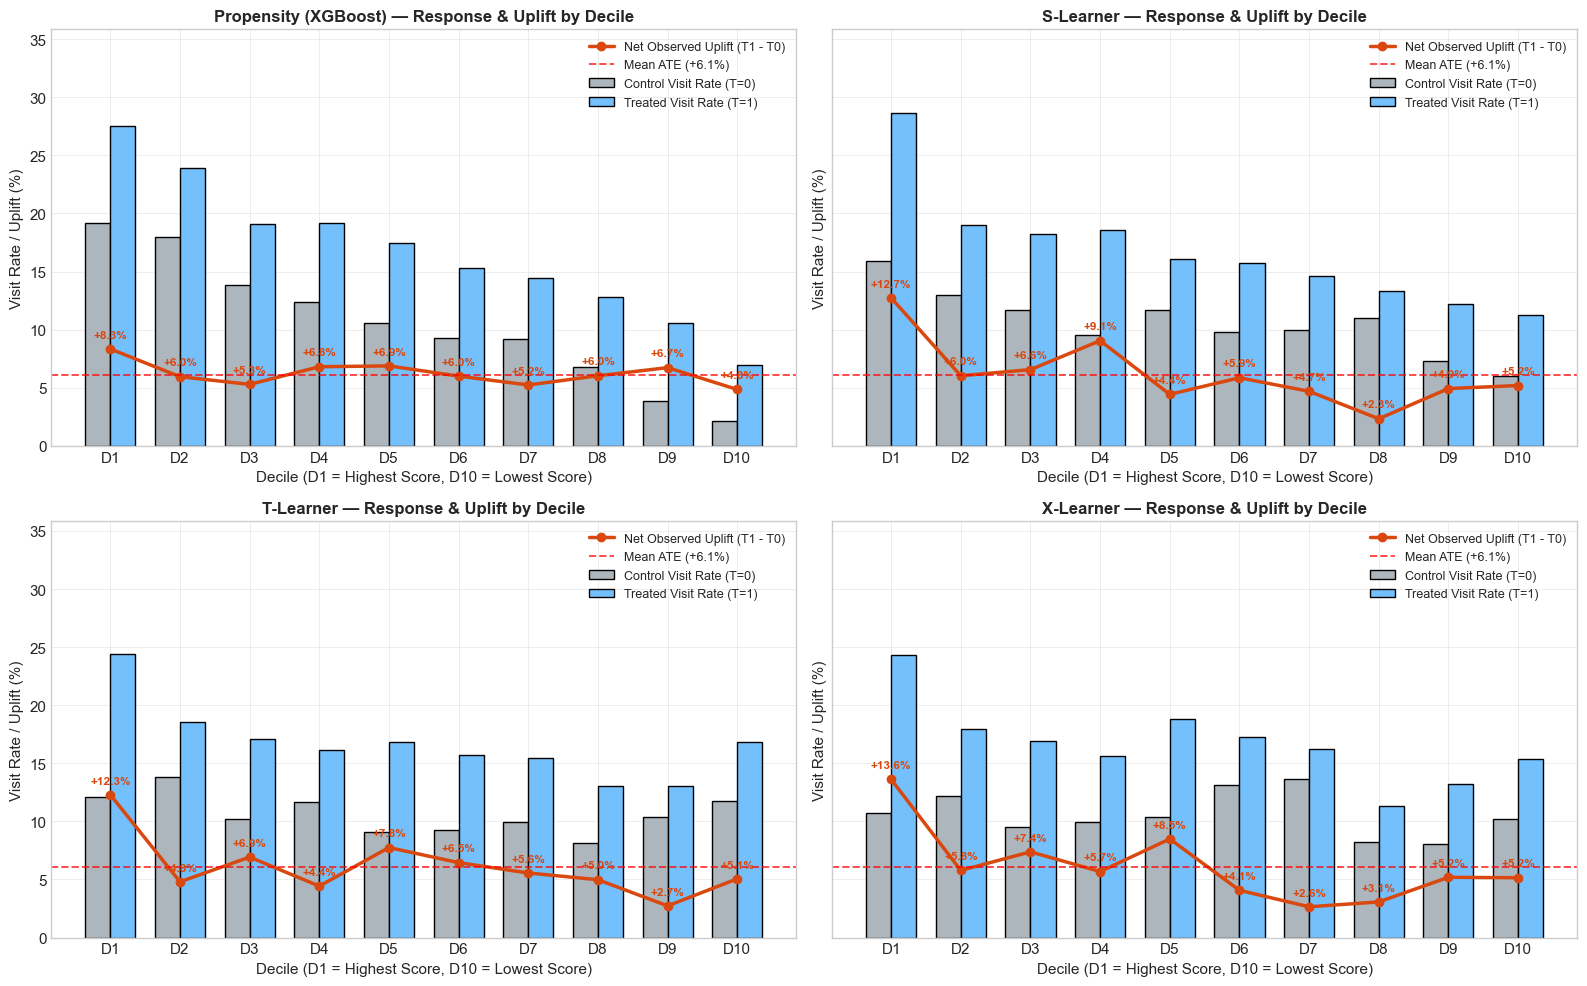

In [18]:
# Plot 2: Detailed 2x2 Per-Model Deciles Breakdown (Treated vs. Control Visit Rate & Net Uplift per Decile)
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
axes = axes.flatten()

for idx, (name, df_d) in enumerate(uplift_deciles_dict.items()):
    ax = axes[idx]
    x = np.arange(len(df_d))
    w = 0.36

    ax.bar(x - w / 2, df_d["Control_Rate_%"], width=w, color="#adb5bd", edgecolor="black", label="Control Visit Rate (T=0)")
    ax.bar(x + w / 2, df_d["Treated_Rate_%"], width=w, color="#74c0fc", edgecolor="black", label="Treated Visit Rate (T=1)")
    ax.plot(x, df_d["Observed_Uplift_%"], "o-", color="#d9480f", linewidth=2.5, markersize=6, label="Net Observed Uplift (T1 - T0)")

    for i, u_val in enumerate(df_d["Observed_Uplift_%"]):
        ax.text(x[i], u_val + 0.8, f"+{u_val:.1f}%", ha="center", va="bottom", fontsize=8.5, color="#d9480f", fontweight="bold")

    ax.axhline(overall_ate_pct, color="red", linestyle="--", alpha=0.7, linewidth=1.4, label=f"Mean ATE (+{overall_ate_pct:.1f}%)")
    ax.set_xticks(x)
    ax.set_xticklabels(df_d["Decile"])
    ax.set_title(f"{name} — Response & Uplift by Decile", fontsize=12, fontweight="bold")
    ax.set_xlabel("Decile (D1 = Highest Score, D10 = Lowest Score)")
    ax.set_ylabel("Visit Rate / Uplift (%)")
    ax.set_ylim(0, max(df_d["Treated_Rate_%"].max(), 32) * 1.12)
    ax.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

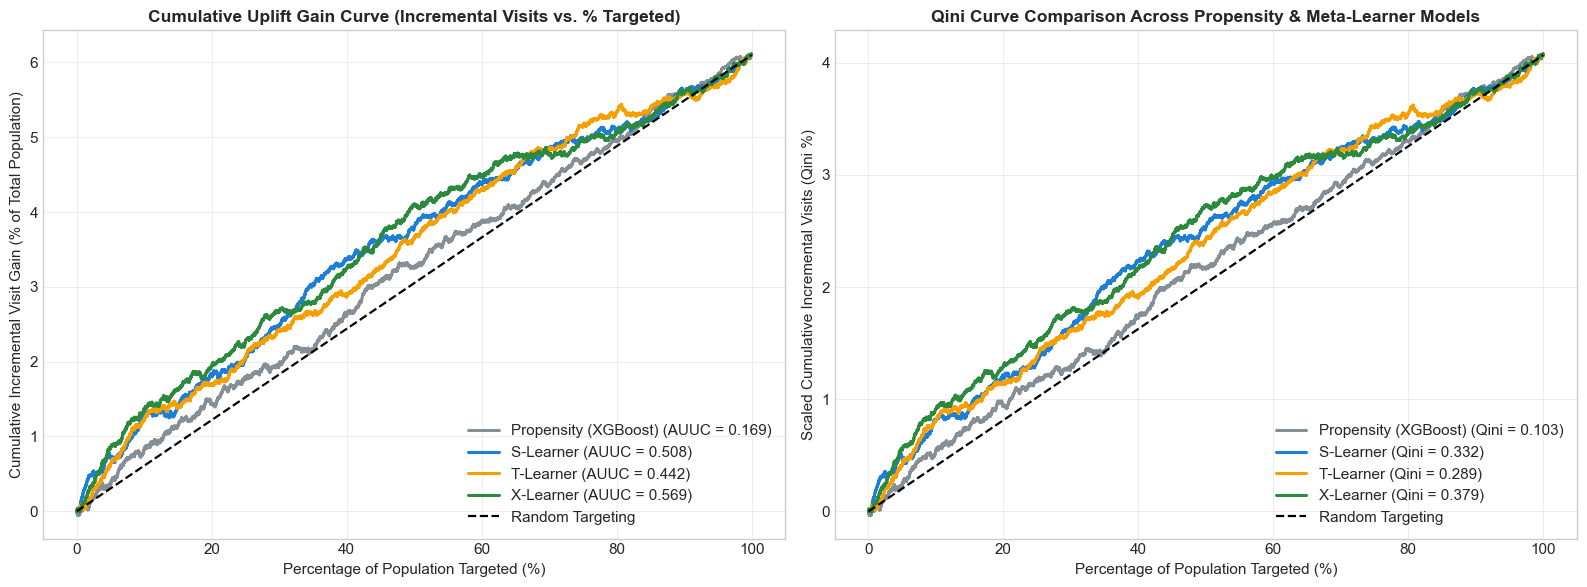

In [19]:
# Plot 3: Cumulative Uplift Gain Curve & Qini Curve Comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, c_data in curves_dict.items():
    pop_pct = c_data["pop_frac"] * 100
    axes[0].plot(
        pop_pct,
        c_data["uplift_curve"] * 100,
        linewidth=2.2,
        color=model_colors[name],
        label=f"{name} (AUUC = {c_data['auuc']*100:.3f})"
    )
    axes[1].plot(
        pop_pct,
        c_data["qini_curve"] * 100,
        linewidth=2.2,
        color=model_colors[name],
        label=f"{name} (Qini = {c_data['qini_coef']*100:.3f})"
    )

# Plot random targeting baseline
ref_curve = next(iter(curves_dict.values()))
axes[0].plot(ref_curve["pop_frac"] * 100, ref_curve["random_uplift"] * 100, "k--", linewidth=1.6, label="Random Targeting")
axes[0].set_title("Cumulative Uplift Gain Curve (Incremental Visits vs. % Targeted)", fontsize=12.5, fontweight="bold")
axes[0].set_xlabel("Percentage of Population Targeted (%)")
axes[0].set_ylabel("Cumulative Incremental Visit Gain (% of Total Population)")
axes[0].legend(loc="lower right")

axes[1].plot(ref_curve["pop_frac"] * 100, ref_curve["random_qini"] * 100, "k--", linewidth=1.6, label="Random Targeting")
axes[1].set_title("Qini Curve Comparison Across Propensity & Meta-Learner Models", fontsize=12.5, fontweight="bold")
axes[1].set_xlabel("Percentage of Population Targeted (%)")
axes[1].set_ylabel("Scaled Cumulative Incremental Visits (Qini %)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# Analytical Conclusions & Reference Summary

1. **Propensity Modeling vs. Causal Uplift Modeling**:
   - In **Part I**, outcome propensity models (`Propensity (LogReg)` and `Propensity (XGBoost)`) effectively ranked customers by their baseline likelihood of visiting the store, achieving a **1.68x conversion lift** in the top decile (`D1` visit rate of `24.64%` vs. `14.68%` population average) and a ROC-AUC of `~0.63`.
   - However, when evaluated causally in **Part II**, ranking by conversion propensity targets many **"Sure Things"** (customers who already have high baseline conversion rates even in the Control group `T=0`). Consequently, its causal uplift in Top 30% (`6.53%`, or `1.07x` over population ATE) and AUUC (`0.00169`) are only marginally better than random targeting.
2. **Comparison of S-Learner, T-Learner, and X-Learner**:
   - **S-Learner (Single-Model)** includes the treatment indicator $T$ as one feature among 18 covariates. Because tree splits do not always partition on $T$, its average predicted uplift (`+5.12%`) is regularized downward relative to the true empirical ATE (`+6.10%`), though it captures strong uplift in `D1` (`12.73%`, `2.09x` lift over ATE) and Top 30% (`8.44%`, `AUUC = 0.00508`).
   - **T-Learner (Two-Model)** trains separate models on Control ($T=0$) and Treated ($T=1$) groups. It eliminates the bias toward zero (`+6.03%` mean predicted uplift) and captures a strong top-decile uplift (`12.29%` in `D1`, `2.02x` lift over ATE), but exhibits higher variance across middle deciles (`AUUC = 0.00442`) because the two base estimators are fitted independently on unequal sample sizes (2:1 Treated-to-Control split).
   - **X-Learner (Cross-Model)** leverages cross-imputed counterfactual residuals weighted by the treatment propensity score $\hat{e}(x) = P(T=1 \mid X=x)$. It achieves the **highest D1 Uplift (`13.61%`, or `2.23x` lift over ATE)**, the **highest Top-30% Uplift (`8.92%`, or `1.46x` lift over ATE)**, and the **highest AUUC (`0.00569`) and Qini coefficient (`0.00379`)**, demonstrating superior stability when treatment and control group sizes are imbalanced.
3. **Practical Decision Rule from Deciles Lift / Uplift Plots**:
   - Rather than emailing 100% of the customer base (which incurs full campaign cost and includes low-uplift deciles `D6`–`D10`), targeting the **Top 30% (Deciles D1–D3)** selected by the **X-Learner** increases campaign efficiency by **+46.3%** (`1.463x` uplift lift) compared to untargeted mass marketing.